# 13 · Probability calibration

## Purpose

Compare reliability of uncalibrated, sigmoid, isotonic, and beta-calibrated probabilities without using the internal final holdout for selection.

## Method

For each outer fold, reserve part of development data for calibration, train the base model on the remaining part, then evaluate the calibrated probabilities on the untouched outer fold. Select the model and calibrator from these CV results.

## Interpretation

Use the displayed tables, figures, and saved metrics produced by this run. Do not fill this section with assumed outcomes. For every result, distinguish observed evidence from interpretation.

## Limitations

Isotonic and beta maps can overfit on small calibration folds. ROC-AUC/PR-AUC measure discrimination, while Brier score, log loss, ECE, and reliability diagrams measure probability quality.

## References

Calibration references: https://proceedings.mlr.press/v54/kull17a.html · https://proceedings.mlr.press/v108/wenger20a.html


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'returnwise').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display
from returnwise.research_state import load_state, save_state
state = load_state()
print('Project:', ROOT)
print('Notebook:', '13 · Probability calibration')


Project: C:\Users\Lenovo\Documents\Who is back
Notebook: 13 · Probability calibration


,fold,method,status,roc_auc,pr_auc,brier_score,log_loss,expected_calibration_error,model
0,1,uncalibrated,completed,0.580042,0.546843,0.244242,0.681498,0.003777,HistGradientBoosting
1,1,sigmoid,completed,0.580042,0.546843,0.244310,0.681640,0.009323,HistGradientBoosting
2,1,isotonic,completed,0.579007,0.539627,0.244533,0.682113,0.011978,HistGradientBoosting
3,1,beta,completed,0.580042,0.546843,0.244310,0.681640,0.009240,HistGradientBoosting
4,2,uncalibrated,completed,0.587749,0.552266,0.243456,0.679900,0.007000,HistGradientBoosting
5,2,sigmoid,completed,0.587749,0.552266,0.243369,0.679720,0.002141,HistGradientBoosting
6,2,isotonic,completed,0.587231,0.546666,0.243529,0.680062,0.006266,HistGradientBoosting
7,2,beta,completed,0.587749,0.552266,0.243373,0.679729,0.003003,HistGradientBoosting
8,3,uncalibrated,completed,0.585809,0.551792,0.243563,0.680097,0.004665,HistGradientBoosting
9,3,sigmoid,completed,0.585809,0.551792,0.243537,0.680041,0.003394,HistGradientBoosting


,model,method,roc_auc,pr_auc,brier_score,log_loss,expected_calibration_error
0,Extra trees,beta,0.564053,0.531047,0.246115,0.685313,0.006110
1,Extra trees,isotonic,0.563222,0.524563,0.246231,0.688060,0.007202
2,Extra trees,sigmoid,0.564053,0.531047,0.246107,0.685297,0.005739
3,Extra trees,uncalibrated,0.564053,0.531047,0.248875,0.691351,0.040299
4,HistGradientBoosting,beta,0.584533,0.550300,0.243738,0.680466,0.004882
5,HistGradientBoosting,isotonic,0.583965,0.543873,0.243892,0.680793,0.007502
6,HistGradientBoosting,sigmoid,0.584533,0.550300,0.243739,0.680467,0.004952
7,HistGradientBoosting,uncalibrated,0.584533,0.550300,0.243754,0.680498,0.005147
8,Logistic regression,beta,0.585251,0.550937,0.243699,0.680391,0.003989
9,Logistic regression,isotonic,0.584620,0.543822,0.243871,0.683325,0.005372


Model selection table with discrimination, calibration, runtime, and memory measurements:


,model,cv_roc_auc,cv_pr_auc,selected_calibrator,brier_score,log_loss,expected_calibration_error,cv_roc_auc_std,cv_pr_auc_std,mean_fit_seconds,mean_inference_seconds,mean_rss_delta_mb,rank_cv_roc_auc,rank_cv_pr_auc,rank_brier_score,rank_log_loss,rank_cv_roc_auc_std,rank_mean_fit_seconds,rank_mean_rss_delta_mb,selection_score
0,Soft voting: HistGradientBoosting + Logistic r...,0.587039,0.553303,beta,0.243406,0.679781,0.004762,0.004070,0.002602,5.260888,0.608663,15.805990,0.25,0.25,0.25,0.25,0.75,0.75,0.75,0.3300
1,Logistic regression,0.585251,0.550937,beta,0.243699,0.680391,0.003989,0.003710,0.002145,2.356295,0.356993,4.045573,0.50,0.50,0.50,0.50,0.25,0.50,0.50,0.4825
2,HistGradientBoosting,0.584533,0.550300,beta,0.243738,0.680466,0.004882,0.004009,0.003004,2.331395,0.412806,0.748698,0.75,0.75,0.75,0.75,0.50,0.25,0.25,0.6875
3,Extra trees,0.564053,0.531047,sigmoid,0.246107,0.685297,0.005739,0.004471,0.002568,7.821213,0.705412,110.040365,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.0000


CV-selected model: Soft voting: HistGradientBoosting + Logistic regression
CV-selected calibrator: beta
Selection is based on training CV only; the final holdout remains untouched.


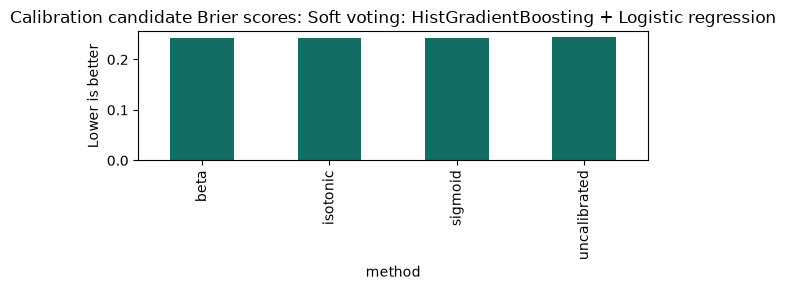

In [2]:
from returnwise.experiments import run_calibration_cv
from returnwise.models import model_registry
from returnwise.research_state import load_state, save_state
import matplotlib.pyplot as plt
import pandas as pd

state = load_state()
cv_parts = [x for x in [state.get('baseline_results'), state.get('advanced_results')] if x is not None]
cv_results = pd.concat(cv_parts, ignore_index=True) if cv_parts else pd.DataFrame()
completed = cv_results[cv_results['status'] == 'completed'].sort_values('roc_auc', ascending=False)
registry, skipped = model_registry(state['X_train'], mode=state.get('experiment_mode', 'quick'))
leaders = [name for name in completed['model'].tolist() if name in registry][:3]
blend_candidate = state.get('selected_ensemble')
if blend_candidate:
    leaders.append(blend_candidate)
if not leaders:
    raise RuntimeError('No validated model candidate is available; run notebooks 09 and 10.')
calibration_folds = pd.concat(
    [run_calibration_cv(
        state['X_train'], state['y_train'], name,
        mode=state.get('experiment_mode', 'quick'), seed=42,
        parameters=(state.get('tuning_result') or {}).get('pipeline_parameters') if (state.get('tuning_result') or {}).get('model') == name else None,
    ).assign(model=name) for name in leaders],
    ignore_index=True,
)
calibration_summary = calibration_folds[calibration_folds['status'] == 'completed'].groupby(['model', 'method'], as_index=False).agg(
    roc_auc=('roc_auc', 'mean'), pr_auc=('pr_auc', 'mean'), brier_score=('brier_score', 'mean'),
    log_loss=('log_loss', 'mean'), expected_calibration_error=('expected_calibration_error', 'mean')
)
display(calibration_folds)
display(calibration_summary)
uncalibrated = calibration_summary[calibration_summary['method'] == 'uncalibrated'].rename(
    columns={'roc_auc': 'cv_roc_auc', 'pr_auc': 'cv_pr_auc'}
)
stability = calibration_folds[(calibration_folds['status'] == 'completed') & (calibration_folds['method'] == 'uncalibrated')].groupby('model', as_index=False).agg(
    cv_roc_auc_std=('roc_auc', 'std'), cv_pr_auc_std=('pr_auc', 'std')
)
calibration_choice = calibration_summary.sort_values(
    ['brier_score', 'log_loss', 'expected_calibration_error']
).groupby('model', as_index=False).first().rename(columns={'method': 'selected_calibrator'})
selection_table = uncalibrated[['model', 'cv_roc_auc', 'cv_pr_auc']].merge(
    calibration_choice[['model', 'selected_calibrator', 'brier_score', 'log_loss', 'expected_calibration_error']],
    on='model', how='inner'
)
selection_table = selection_table.merge(stability, on='model', how='left')
timing_parts = [x[x['status'] == 'completed'] for x in [state.get('baseline_results'), state.get('advanced_results')] if x is not None]
timing = pd.concat(timing_parts, ignore_index=True).groupby('model', as_index=False).agg(
    mean_fit_seconds=('mean_fit_seconds', 'mean'), mean_inference_seconds=('mean_inference_seconds', 'mean'),
    mean_rss_delta_mb=('mean_rss_delta_mb', 'mean')
) if timing_parts else pd.DataFrame()
selection_table = selection_table.merge(timing, on='model', how='left')
if blend_candidate:
    blend_name = blend_candidate.replace('Soft voting: ', 'OOF mean: ')
    blend_row = state['blend_results'].loc[state['blend_results']['blend'] == blend_name].iloc[0]
    fold_count = 3 if state.get('experiment_mode', 'quick') == 'quick' else 5
    selection_table.loc[selection_table['model'] == blend_candidate, 'mean_fit_seconds'] = blend_row['fit_seconds_total'] / fold_count
    selection_table.loc[selection_table['model'] == blend_candidate, 'mean_inference_seconds'] = blend_row['inference_seconds_total'] / fold_count
    selection_table.loc[selection_table['model'] == blend_candidate, 'mean_rss_delta_mb'] = blend_row['rss_delta_mb_total'] / fold_count
for metric, ascending in [('cv_roc_auc', False), ('cv_pr_auc', False), ('brier_score', True),
                          ('log_loss', True), ('cv_roc_auc_std', True),
                          ('mean_fit_seconds', True), ('mean_rss_delta_mb', True)]:
    selection_table[f'rank_{metric}'] = selection_table[metric].rank(pct=True, ascending=ascending)
selection_table['selection_score'] = (
    0.28 * selection_table['rank_cv_roc_auc'] + 0.18 * selection_table['rank_cv_pr_auc']
    + 0.24 * selection_table['rank_brier_score'] + 0.14 * selection_table['rank_log_loss']
    + 0.07 * selection_table['rank_cv_roc_auc_std'] + 0.05 * selection_table['rank_mean_fit_seconds']
    + 0.04 * selection_table['rank_mean_rss_delta_mb']
)
selection_table = selection_table.sort_values('selection_score').reset_index(drop=True)
selected_model = selection_table.iloc[0]['model']
selected_calibrator = selection_table.iloc[0]['selected_calibrator']
print('Model selection table with discrimination, calibration, runtime, and memory measurements:')
display(selection_table)
print('CV-selected model:', selected_model)
print('CV-selected calibrator:', selected_calibrator)
print('Selection is based on training CV only; the final holdout remains untouched.')
chart = calibration_summary[calibration_summary['model'] == selected_model].set_index('method')['brier_score']
ax = chart.plot.bar(figsize=(6, 3), color='#126E63', title=f'Calibration candidate Brier scores: {selected_model}')
ax.set_ylabel('Lower is better')
plt.tight_layout()
plt.show()
state.update({'calibration_folds': calibration_folds, 'calibration_summary': calibration_summary,
              'selection_table': selection_table, 'selected_model': selected_model,
              'selected_calibrator': selected_calibrator})
from returnwise.experiments import log_experiment
log_experiment('Probability calibration and model selection', None,
               {'selection': selection_table.to_dict(orient='records'),
                'calibration': calibration_summary.to_dict(orient='records')},
               {'selected_model': selected_model, 'selected_calibrator': selected_calibrator})
save_state(state)
